
<div style="background-color:#dff2e1; padding:16px; border-radius:8px;">
<h1 style="margin-bottom:4px;">Industrial Data Analytics</h1>
<h2 style="margin-top:4px;">Practical Session 2 - Introduction to Python for Industrial Data Analytics</h2>
</div>

### Connection to Lecture 2
Lecture 2 introduced four approaches to data analytics:

- **Descriptive analytics** - What happened?
- **Diagnostic analytics** - Why did it happen?
- **Predictive analytics** - What is likely to happen next?
- **Prescriptive analytics** - What action should we take?

In this practical you will begin using Python to work with industrial sensor data. Most of today's coding focuses on **descriptive analytics**, with a short introduction to **diagnostic analytics**.

> **Important:** Work through Part 1 in order. Run each code cell using **Shift + Enter** and read the comments before moving to the next cell.



## Learning objectives

By the end of this practical you should be able to:

1. Create Python variables using common data types.
2. Use `if`, `elif`, and `else` to make simple engineering decisions.
3. Use lists, loops, and functions to process repeated sensor readings.
4. Import a CSV file into a pandas DataFrame.
5. Calculate simple descriptive statistics from industrial data.
6. Produce a basic line graph using Matplotlib.
7. Explain how a simple correlation can support diagnostic analytics.



# Part 1 - Guided Practical




## 1. Variables and data types

Industrial systems generate different types of information. A temperature reading is usually a decimal number, a sensor identifier may be a whole number, and an operating state may be stored as text or as a Boolean value.


In [2]:
# Store a temperature measurement as a floating-point number in degrees Celsius.
temperature = 27.3

# Store a pressure measurement as a floating-point number in kilopascals.
pressure = 102.5

# Store the current operating state of the machine as text.
status = "Active"

# Store a unique sensor identifier as an integer.
sensor_id = 1234

# Store whether the sensor is working as a Boolean value.
is_sensor_working = True


In [4]:
# Display the value stored in the temperature variable.
print("Temperature:", temperature)

# Display the value stored in the pressure variable.
print("Pressure:", pressure)

# Display the text stored in the status variable.
print("System status:", status)

# Display the integer stored in the sensor_id variable.
print("Sensor ID:", sensor_id)

# Display the Boolean value that shows whether the sensor is operating.
print("Is the sensor working?", is_sensor_working)


Temperature: 27.3
Pressure: 102.5
System status: Active
Sensor ID: 1234
Is the sensor working? True


In [6]:
# Display the Python data type of the temperature variable.
print("temperature is:", type(temperature))

# Display the Python data type of the pressure variable.
print("pressure is:", type(pressure))

# Display the Python data type of the status variable.
print("status is:", type(status))

# Display the Python data type of the sensor_id variable.
print("sensor_id is:", type(sensor_id))

# Display the Python data type of the is_sensor_working variable.
print("is_sensor_working is:", type(is_sensor_working))


temperature is: <class 'float'>
pressure is: <class 'float'>
status is: <class 'str'>
sensor_id is: <class 'int'>
is_sensor_working is: <class 'bool'>



### Check your understanding
- Why are `temperature` and `pressure` stored as `float` values?
- Why might a sensor ID be stored as an `int` rather than a `float`?
- What are the only two values a Boolean variable can store?



## 2. Making decisions with `if`, `elif`, and `else`

A monitoring program can compare a measurement with engineering limits and then decide which message should be displayed.

For this example:

- temperatures above **35 °C** are considered too high;
- temperatures below **10 °C** are considered too low;
- temperatures between these limits are considered normal.


In [8]:
# Check whether the measured temperature is above the upper safe limit.
if temperature > 35:
    # Display a warning if the temperature is too high.
    print("Warning: Temperature is too high!")

# Check whether the temperature is below the lower safe limit if the first condition was False.
elif temperature < 10:
    # Display a warning if the temperature is too low.
    print("Warning: Temperature is too low!")

# Run this block if neither of the previous conditions was True.
else:
    # Display a message showing that the temperature is inside the normal range.
    print("Temperature is within the normal range.")


Temperature is within the normal range.



### Try it
Change the value of `temperature` in the earlier cell and run the cells again. Test at least:

- one value above 35 °C;
- one value below 10 °C;
- one value between 10 °C and 35 °C.

Then restore the original value before continuing.



## 3. Lists and loops

A real sensor produces many readings rather than only one. A Python **list** can store a sequence of measurements, and a **loop** allows us to process each measurement in turn.


In [10]:
# Create a list containing five temperature measurements in degrees Celsius.
temperatures = [25.6, 26.1, 27.8, 28.2, 29.5]

# Start a loop that takes one value at a time from the temperatures list.
for temp in temperatures:
    # Display the current temperature value selected by the loop.
    print(f"Temperature reading: {temp} °C")


Temperature reading: 25.6 °C
Temperature reading: 26.1 °C
Temperature reading: 27.8 °C
Temperature reading: 28.2 °C
Temperature reading: 29.5 °C


In [12]:
# Start a loop that generates the numbers 0, 1, 2, 3, and 4.
for i in range(5):
    # Display a human-friendly reading number by adding 1 to the loop counter.
    print(f"Reading {i + 1}: {temperatures[i]} °C")


Reading 1: 25.6 °C
Reading 2: 26.1 °C
Reading 3: 27.8 °C
Reading 4: 28.2 °C
Reading 5: 29.5 °C



Notice that Python starts counting positions from **0**. Therefore, the first item in a list is at position `0`, the second at position `1`, and so on.



## 4. Functions

A function allows us to package a calculation so that it can be reused. Here we will create a function that calculates the average of a collection of sensor readings.


In [14]:
# Define a reusable function called calculate_average that accepts a set of readings.
def calculate_average(readings):
    # Add all values in the readings collection.
    total = sum(readings)

    # Count how many values are stored in the readings collection.
    count = len(readings)

    # Divide the total by the number of readings to calculate the arithmetic mean.
    average = total / count

    # Send the calculated average back to the line of code that called the function.
    return average


In [16]:
# Call the calculate_average function using the temperatures list and store the returned result.
average_temperature = calculate_average(temperatures)

# Display the calculated average temperature.
print("Average temperature:", average_temperature, "°C")


Average temperature: 27.439999999999998 °C



This is our first simple example of **descriptive analytics**: we are taking several historical measurements and summarising them with one statistic.



## 5. Reading industrial data from a CSV file

Industrial data is often stored in tabular files. A CSV file contains values separated by commas and can be imported into Python using **pandas**.

The supplied file `sensor_data.csv` contains:

- `Time` - time in seconds;
- `Temperature` - temperature in °C;
- `Pressure` - pressure in kPa.

Make sure `sensor_data.csv` is saved in the **same folder** as this notebook.


In [18]:
# Import the pandas library and use the standard abbreviation pd.
import pandas as pd

# Read the CSV file and store the resulting table in a pandas DataFrame called data.
data = pd.read_csv("sensor_data.csv")


In [20]:
# Display the first five rows of the DataFrame so that we can check the imported data.
print(data.head())


   Time  Temperature  Pressure
0     0         25.6     101.2
1     1         26.1     101.5
2     2         27.8     102.1
3     3         28.2     102.3
4     4         29.5     102.8


In [22]:
# Display the number of rows and columns in the DataFrame.
print("DataFrame shape:", data.shape)

# Display the names of all columns in the DataFrame.
print("Column names:", data.columns.tolist())

# Display the data type used by pandas for each column.
print("\nColumn data types:")
print(data.dtypes)


DataFrame shape: (5, 3)
Column names: ['Time', 'Temperature', 'Pressure']

Column data types:
Time             int64
Temperature    float64
Pressure       float64
dtype: object



### Why inspect the data first?
Before analysing a dataset, always check that:

- the file loaded correctly;
- the expected columns are present;
- numeric columns have been recognised as numbers;
- the number of observations looks sensible.

This habit becomes especially important when working with larger industrial datasets.



## 6. Descriptive analytics with sensor data

We can now answer questions such as:

- What was the average temperature?
- What were the minimum and maximum values?
- How much did the readings vary?


In [24]:
# Calculate the mean value of the Temperature column.
mean_temperature = data["Temperature"].mean()

# Find the minimum value in the Temperature column.
min_temperature = data["Temperature"].min()

# Find the maximum value in the Temperature column.
max_temperature = data["Temperature"].max()

# Calculate the range of the temperature readings.
temperature_range = max_temperature - min_temperature

# Calculate the standard deviation of the temperature readings.
std_temperature = data["Temperature"].std()

# Calculate the mean value of the Pressure column.
mean_pressure = data["Pressure"].mean()

# Find the maximum value in the Pressure column.
max_pressure = data["Pressure"].max()


In [26]:
# Display the average temperature rounded to two decimal places.
print(f"Mean temperature: {mean_temperature:.2f} °C")

# Display the minimum temperature.
print(f"Minimum temperature: {min_temperature:.2f} °C")

# Display the maximum temperature.
print(f"Maximum temperature: {max_temperature:.2f} °C")

# Display the calculated temperature range.
print(f"Temperature range: {temperature_range:.2f} °C")

# Display the temperature standard deviation rounded to two decimal places.
print(f"Temperature standard deviation: {std_temperature:.2f} °C")

# Display the average pressure rounded to two decimal places.
print(f"Mean pressure: {mean_pressure:.2f} kPa")

# Display the maximum pressure rounded to two decimal places.
print(f"Maximum pressure: {max_pressure:.2f} kPa")


Mean temperature: 27.44 °C
Minimum temperature: 25.60 °C
Maximum temperature: 29.50 °C
Temperature range: 3.90 °C
Temperature standard deviation: 1.59 °C
Mean pressure: 101.98 kPa
Maximum pressure: 102.80 kPa


In [28]:
# Ask pandas to calculate a standard set of descriptive statistics for all numeric columns.
summary_statistics = data.describe()

# Display the statistical summary table.
print(summary_statistics)


           Time  Temperature    Pressure
count  5.000000      5.00000    5.000000
mean   2.000000     27.44000  101.980000
std    1.581139      1.59154    0.637966
min    0.000000     25.60000  101.200000
25%    1.000000     26.10000  101.500000
50%    2.000000     27.80000  102.100000
75%    3.000000     28.20000  102.300000
max    4.000000     29.50000  102.800000



These calculations are **descriptive analytics** because they summarise what has already been measured.

In later practicals, we will work with larger datasets and use more advanced statistical methods.



## 7. Visualising the sensor measurements

A graph can reveal a pattern that is difficult to see from a table of numbers. We will first plot temperature against time.


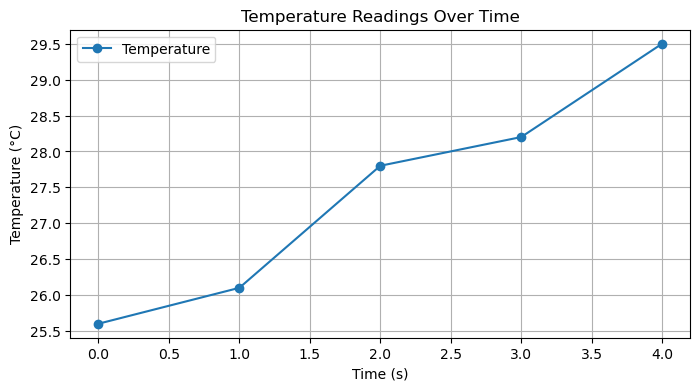

In [30]:
# Import the pyplot section of Matplotlib and use the standard abbreviation plt.
import matplotlib.pyplot as plt

# Create a new figure with a width of 8 inches and a height of 4 inches.
plt.figure(figsize=(8, 4))

# Plot Time on the horizontal axis and Temperature on the vertical axis.
plt.plot(data["Time"], data["Temperature"], marker="o", label="Temperature")

# Add a descriptive label to the horizontal axis.
plt.xlabel("Time (s)")

# Add a descriptive label and unit to the vertical axis.
plt.ylabel("Temperature (°C)")

# Add a title that explains what the graph shows.
plt.title("Temperature Readings Over Time")

# Display the label defined in the plot command.
plt.legend()

# Add grid lines to make values easier to read from the graph.
plt.grid(True)

# Display the completed graph inside the notebook.
plt.show()



### Interpreting the graph
Do not stop after producing a figure. Ask what the figure tells you.

For this dataset, consider:

- Is the temperature increasing, decreasing, or staying approximately constant?
- Is the change smooth or irregular?
- Which reading has the highest temperature?

These questions turn plotting into **data analysis** rather than simply graph drawing.



## 8. A first step towards diagnostic analytics

Lecture 2 introduced **correlation analysis** as a diagnostic technique. Correlation measures how strongly two numerical variables change together.

A correlation coefficient:

- close to **+1** indicates a strong positive relationship;
- close to **0** indicates little linear relationship;
- close to **-1** indicates a strong negative relationship.

> Correlation can indicate a relationship, but it does **not** by itself prove that one variable causes the other.


In [32]:
# Calculate the Pearson correlation coefficient between Temperature and Pressure.
temperature_pressure_correlation = data["Temperature"].corr(data["Pressure"])

# Display the correlation coefficient rounded to three decimal places.
print(f"Correlation between temperature and pressure: {temperature_pressure_correlation:.3f}")


Correlation between temperature and pressure: 0.998



### Think about the result
If the correlation is strongly positive, the two variables tend to rise together in this dataset. That gives us a clue for a **diagnostic** question, but we would need more data and engineering knowledge before claiming a cause-and-effect relationship.



## 9. Connecting today's work to the four analytics approaches

| Analytics approach | Question | Example using this sensor system |
|---|---|---|
| **Descriptive** | What happened? | What were the mean, minimum, and maximum temperature values? |
| **Diagnostic** | Why did it happen? | Is the change in temperature associated with a change in pressure? |
| **Predictive** | What may happen next? | What temperature might be measured at the next time step? |
| **Prescriptive** | What should we do? | Should the controller reduce load or activate additional cooling? |

Today we have mainly implemented **descriptive analytics** and taken a small first step towards **diagnostic analytics**. Predictive and prescriptive methods will be developed later in the module.



# Part 2 - Student Exercise

## Industrial cooling-system sensor check

You are reviewing data collected from a small industrial cooling system. The file `sensor_data.csv` contains temperature and pressure measurements recorded over time.

Your task is to carry out a short analysis **without copying the completed code from Part 1**. Use Part 1 as a reference when you are unsure of the Python syntax.

### Task 1 - Load and inspect the data
1. Import the libraries you need.
2. Load `sensor_data.csv` into a DataFrame.
3. Display the first five rows.
4. Display the number of rows and columns.
5. Display the column names.

**Hint:** You have already used `pd.read_csv()`, `.head()`, `.shape`, and `.columns` in Part 1.


In [ ]:
# Write your code for Task 1 below.




### Task 2 - Calculate descriptive statistics
Calculate and display:

1. mean pressure;
2. minimum pressure;
3. maximum pressure;
4. pressure range;
5. standard deviation of pressure;
6. mean temperature.

Add appropriate units to your printed results.

**Hint:** The pressure range is:

`maximum pressure - minimum pressure`


In [ ]:
# Write your code for Task 2 below.




### Task 3 - Apply an engineering decision rule

For this exercise, use the following simple operating rule:

- **Normal:** temperature is 28.0 °C or lower;
- **High-temperature alert:** temperature is greater than 28.0 °C.

Use the **maximum temperature in the dataset** and an `if`/`else` statement to display either:

- `High-temperature alert`
- or `Temperature remained within the exercise limit`

**Hint:** First calculate the maximum temperature and store it in a variable. Then compare that variable with `28.0`.


In [ ]:
# Write your code for Task 3 below.




### Task 4 - Visualise pressure over time

Create a line graph showing **Pressure against Time**.

Your graph must include:

- a line joining the readings;
- a visible marker at each measurement;
- x-axis label with unit;
- y-axis label with unit;
- a meaningful title;
- grid lines.

**Hint:** Use the temperature graph from Part 1 as a pattern, but change the variable plotted on the y-axis.


In [ ]:
# Write your code for Task 4 below.




### Task 5 - Investigate a possible relationship

Calculate the correlation coefficient between **Temperature** and **Pressure**.

Then write **two or three sentences** below your code answering:

1. Is the relationship positive, negative, or close to zero?
2. Is it weak or strong?
3. Why should you avoid saying that correlation proves causation?

**Hint:** In Part 1 we used the `.corr()` method.


In [ ]:
# Write your code for Task 5 below.




**Write your interpretation here:**

- 
- 



### Task 6 - Identify the analytics approach

For each statement below, identify whether it is **descriptive**, **diagnostic**, **predictive**, or **prescriptive** analytics.

1. Calculate the average pressure measured during the test.
2. Investigate whether rising temperature is associated with rising pressure.
3. Estimate the pressure expected at the next measurement.
4. Recommend whether the controller should activate additional cooling.

**Write your answers here:**

1.  
2.  
3.  
4.  



## Optional challenge

Use a `for` loop to examine every temperature value in the `Temperature` column.

For each reading:

- print the reading number;
- print the temperature;
- display `ALERT` if the temperature is greater than 28.0 °C;
- otherwise display `NORMAL`.

Try to complete this using the examples of lists, loops, and `if` statements from Part 1.

> This challenge is optional. Attempt it only after completing Tasks 1-6.


In [ ]:
# Write your optional challenge code below.




# End-of-practical reflection

Before you finish, make sure you can answer these questions in your own words:

- What is the difference between a Python variable and a list?
- Why is a DataFrame useful for industrial data?
- What does the mean tell us about a set of measurements?
- Why can a graph be more informative than looking only at raw numbers?
- What is the difference between descriptive and diagnostic analytics?
- Why does correlation not automatically mean causation?

### Save your work
Save your notebook before leaving the session. Your solution to **Part 2** will be discussed in the next practical so that you can compare your approach with a worked solution.
